In [1]:
!pip install -q kagglehub mediapipe
!wget -q -O hand_landmarker.task https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task

import glob, os, re, time
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import mediapipe as mp
from mediapipe.tasks import python as mp_tasks
from mediapipe.tasks.python import vision

path = kagglehub.dataset_download("grassknoted/asl-alphabet")

options = vision.HandLandmarkerOptions(
    base_options=mp_tasks.BaseOptions(model_asset_path="hand_landmarker.task"),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=1,
    min_hand_detection_confidence=0.3,
)
detector = vision.HandLandmarker.create_from_options(options)

LETTERS = list("ABCDEFGHIKLMNOPQRSTUVWXY")

def letter_files(letter):
    files = glob.glob(f"{path}/**/asl_alphabet_train/{letter}/*.jpg", recursive=True)
    return sorted(files, key=lambda p: int(re.findall(r"\d+", os.path.basename(p))[0]))

def to_features(landmarks):
    pts = np.array([[lm.x, lm.y] for lm in landmarks])
    pts = pts - pts[0]
    pts = pts / np.abs(pts).max()
    return pts.flatten()

def extract(files):
    feats = []
    for f in files:
        res = detector.detect(mp.Image.create_from_file(f))
        if res.hand_landmarks:
            feats.append(to_features(res.hand_landmarks[0]))
    return feats

print("Letters:", len(LETTERS), LETTERS)
print("A photos:", len(letter_files("A")))
print("Setup ready ✅")

Using Colab cache for faster access to the 'asl-alphabet' dataset.
Letters: 24 ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
A photos: 3000
Setup ready ✅


In [2]:
X_train, y_train, X_test, y_test = [], [], [], []
start = time.time()

for label, letter in enumerate(LETTERS):
    files = letter_files(letter)
    tr = extract(files[0:2000:5])
    te = extract(files[2400:3000:5])
    X_train += tr; y_train += [label] * len(tr)
    X_test  += te; y_test  += [label] * len(te)
    print(f"{letter}: train {len(tr):3d}/400  test {len(te):3d}/120   ({time.time() - start:.0f}s)")

X_train, X_test = np.array(X_train, dtype=np.float32), np.array(X_test, dtype=np.float32)
y_train, y_test = np.array(y_train), np.array(y_test)
print("\nX_train:", X_train.shape, " X_test:", X_test.shape)
np.savez("landmarks_24letters.npz", X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test)
print("Saved ✅")

A: train 339/400  test  43/120   (46s)
B: train 339/400  test  32/120   (94s)
C: train 334/400  test  32/120   (139s)
D: train 381/400  test  56/120   (187s)
E: train 351/400  test  42/120   (214s)
F: train 386/400  test 119/120   (259s)
G: train 371/400  test  65/120   (287s)
H: train 392/400  test  35/120   (339s)
I: train 388/400  test  34/120   (373s)
K: train 390/400  test  78/120   (427s)
L: train 381/400  test  72/120   (461s)
M: train 292/400  test  33/120   (511s)
N: train 235/400  test  26/120   (543s)
O: train 382/400  test  52/120   (597s)
P: train 356/400  test  19/120   (632s)
Q: train 383/400  test  31/120   (684s)
R: train 381/400  test  69/120   (721s)
S: train 389/400  test  72/120   (769s)
T: train 383/400  test  32/120   (799s)
U: train 370/400  test  64/120   (840s)
V: train 364/400  test  79/120   (868s)
W: train 362/400  test  73/120   (909s)
X: train 366/400  test  29/120   (937s)
Y: train 396/400  test  51/120   (977s)

X_train: (8711, 42)  X_test: (1238, 42)
S

In [3]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_t = torch.from_numpy(X_train)
y_train_t = torch.from_numpy(y_train).long()
X_test_t  = torch.from_numpy(X_test)
y_test_t  = torch.from_numpy(y_test).long()

train_ds = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)

xb, yb = next(iter(train_loader))
print("One batch X:", xb.shape, xb.dtype)
print("One batch y:", yb.shape, yb.dtype)
print("First 10 labels:", [LETTERS[i] for i in yb[:10]])
print("Batches per epoch:", len(train_loader))

One batch X: torch.Size([64, 42]) torch.float32
One batch y: torch.Size([64]) torch.int64
First 10 labels: ['A', 'T', 'C', 'W', 'M', 'O', 'H', 'R', 'D', 'D']
Batches per epoch: 137


In [4]:
import torch.nn as nn

class LandmarkMLP(nn.Module):
    def __init__(self, n_in=42, n_classes=24):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 128), nn.ReLU(),
            nn.Linear(128, 64),   nn.ReLU(),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
model = LandmarkMLP()
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

loss_fn = nn.CrossEntropyLoss()
logits = model(xb)
print("Output shape:", logits.shape)
print("Loss:", round(loss_fn(logits, yb).item(), 3), " (random guess ≈", round(np.log(24), 3), ")")

LandmarkMLP(
  (net): Sequential(
    (0): Linear(in_features=42, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=24, bias=True)
  )
)
Parameters: 15320
Output shape: torch.Size([64, 24])
Loss: 3.177  (random guess ≈ 3.178 )


epoch  1  loss 2.127  test acc 61.0%
epoch  5  loss 0.290  test acc 85.1%
epoch 10  loss 0.147  test acc 87.9%
epoch 15  loss 0.097  test acc 90.2%
epoch 20  loss 0.075  test acc 89.8%
epoch 25  loss 0.060  test acc 90.7%
epoch 30  loss 0.050  test acc 91.6%

Total training time: 7.0s


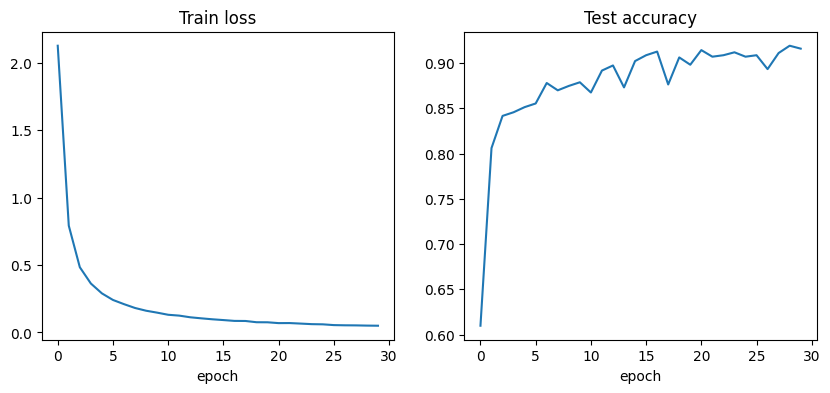

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs = 30
train_losses, test_accs = [], []

start = time.time()
for epoch in range(epochs):
    model.train()
    total = 0.0
    for xb, yb in train_loader:
        logits = model(xb)
        loss = loss_fn(logits, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    train_losses.append(total / len(train_ds))

    model.eval()
    with torch.no_grad():
        test_acc = (model(X_test_t).argmax(dim=1) == y_test_t).float().mean().item()
    test_accs.append(test_acc)

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"epoch {epoch+1:2d}  loss {train_losses[-1]:.3f}  test acc {test_acc:.1%}")

print(f"\nTotal training time: {time.time() - start:.1f}s")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(train_losses); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(test_accs);    ax[1].set_title("Test accuracy"); ax[1].set_xlabel("epoch")
plt.savefig("day4_training.png"); plt.show()

In [6]:
from collections import Counter

model.eval()
with torch.no_grad():
    test_preds = model(X_test_t).argmax(dim=1).numpy()
    train_acc = (model(X_train_t).argmax(dim=1) == y_train_t).float().mean().item()

print(f"Train accuracy: {train_acc:.1%}")
print(f"Test accuracy:  {(test_preds == y_test).mean():.1%}\n")

print("Per letter (worst first):")
per_letter = []
for k, letter in enumerate(LETTERS):
    mask = y_test == k
    per_letter.append((letter, (test_preds[mask] == k).mean(), mask.sum()))
for letter, acc, n in sorted(per_letter, key=lambda t: t[1]):
    print(f"  {letter}: {acc:5.0%}  ({n} photos)")

print("\nTop confusions (true → predicted):")
mistakes = Counter((LETTERS[t], LETTERS[p]) for t, p in zip(y_test, test_preds) if t != p)
for (t, p), count in mistakes.most_common(8):
    print(f"  {t} → {p}: {count} times")

Train accuracy: 98.9%
Test accuracy:  91.6%

Per letter (worst first):
  N:   62%  (26 photos)
  M:   64%  (33 photos)
  D:   64%  (56 photos)
  A:   65%  (43 photos)
  P:   68%  (19 photos)
  T:   84%  (32 photos)
  R:   86%  (69 photos)
  S:   89%  (72 photos)
  Y:   94%  (51 photos)
  E:   95%  (42 photos)
  U:   95%  (64 photos)
  C:   97%  (32 photos)
  I:   97%  (34 photos)
  H:   97%  (35 photos)
  W:   97%  (73 photos)
  K:   97%  (78 photos)
  V:   97%  (79 photos)
  G:   98%  (65 photos)
  B:  100%  (32 photos)
  F:  100%  (119 photos)
  L:  100%  (72 photos)
  O:  100%  (52 photos)
  Q:  100%  (31 photos)
  X:  100%  (29 photos)

Top confusions (true → predicted):
  D → O: 15 times
  M → N: 11 times
  N → M: 10 times
  R → U: 7 times
  A → Y: 6 times
  A → M: 5 times
  D → U: 4 times
  P → Q: 4 times


In [7]:
torch.save({"state_dict": model.state_dict(), "letters": LETTERS}, "asl_mlp.pt")

check = LandmarkMLP()
saved = torch.load("asl_mlp.pt")
check.load_state_dict(saved["state_dict"])
check.eval()
with torch.no_grad():
    acc = (check(X_test_t).argmax(dim=1) == y_test_t).float().mean().item()
print(f"Reloaded model test accuracy: {acc:.1%}")
print("File size:", round(os.path.getsize("asl_mlp.pt") / 1024), "KB")

Reloaded model test accuracy: 91.6%
File size: 63 KB
